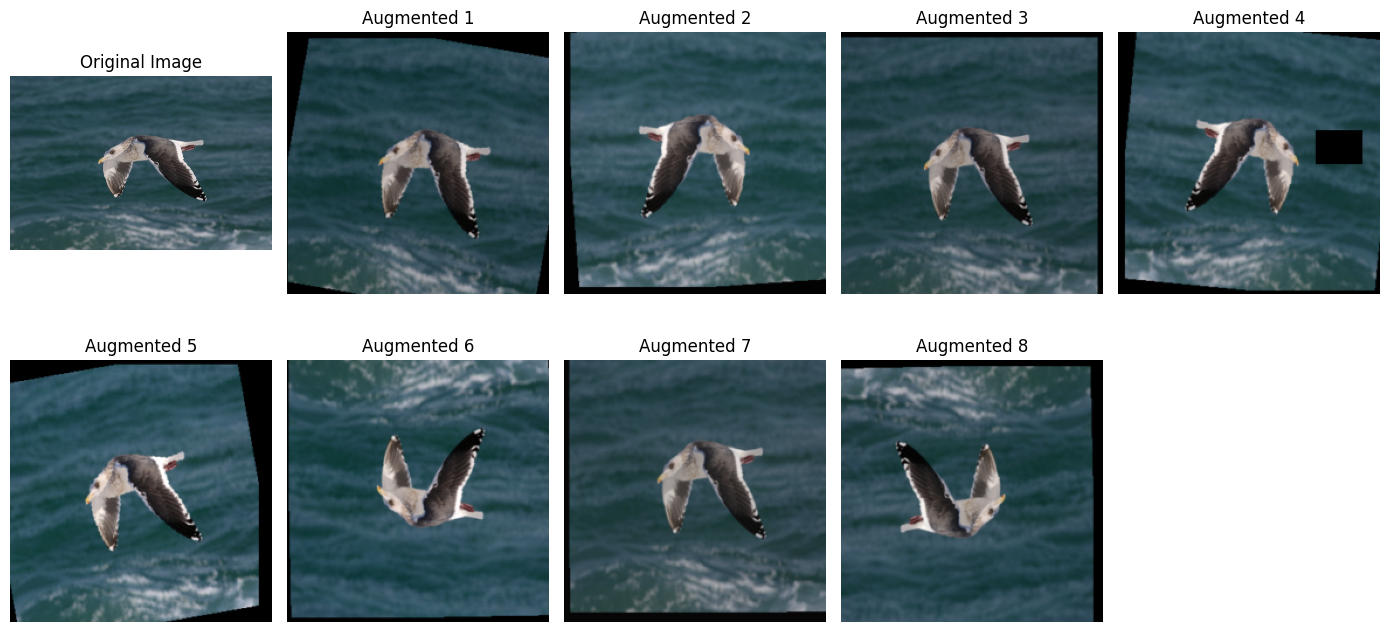

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as transforms

# Set dataset path (Update this if needed)
dataset_path = "/content/drive/My Drive/FYP/Dataset/HQ3/train"

# Select a random class folder from dataset
class_folder = random.choice(os.listdir(dataset_path))
class_path = os.path.join(dataset_path, class_folder)

# Select a random image from that class
image_file = random.choice(os.listdir(class_path))
image_path = os.path.join(class_path, image_file)

# Load the image
original_image = Image.open(image_path)

# Define Augmentations (NO MORE BLUR!)
pil_transforms = transforms.Compose([
    transforms.Resize((300, 300)),  # Instead of 224x224, use 256x256  # Resize to match VGG input
    transforms.RandomHorizontalFlip(p=0.5),  # Flip left/right
    transforms.RandomVerticalFlip(p=0.3),  # Flip up/down (not too often)
    transforms.RandomRotation(degrees=10),  # Slight rotations to simulate natural variations (was 15)
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),  # Minor translation to shift position (reduced from 0.1)
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),  # Very slight color variations (reduced from 0.2)
    transforms.RandomResizedCrop(224, scale=(0.95, 1.0)),  # Less aggressive cropping (previously 0.85)
    transforms.RandomAdjustSharpness(sharpness_factor=1.2, p=0.3),  # Keep mild sharpness (was 1.5)
])

# Convert to Tensor and Apply Tensor-Specific Transformations
tensor_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.1, scale=(0.02, 0.05)),  # Reduce small area removal (was 0.2)
])

# Generate augmented versions of the image
num_augmentations = 8  # Number of different augmentations to display
augmented_images = []
for _ in range(num_augmentations):
    img = pil_transforms(original_image)  # Apply PIL-based augmentations
    img = tensor_transforms(img)  # Convert to tensor and apply tensor-based transforms
    augmented_images.append(img)

# Convert tensors back to PIL for visualization
augmented_images = [transforms.ToPILImage()(img) for img in augmented_images]

# Display original vs. augmented images
plt.figure(figsize=(14, 7))
plt.subplot(2, num_augmentations//2 + 1, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

for i, aug_img in enumerate(augmented_images):
    plt.subplot(2, num_augmentations//2 + 1, i+2)
    plt.imshow(aug_img)
    plt.title(f"Augmented {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


Using device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch [1/20], Loss: 0.364264
Validation Accuracy: 78.95%
Current model saved at /content/drive/My Drive/FYP/VGGModel/Improved_20250210/current_model_vgg_improved.pth
New best model saved with accuracy: 78.95% at /content/drive/My Drive/FYP/VGGModel/Improved_20250210/best_model_vgg_improved_20250210.pth
Epoch [2/20], Loss: 0.145260
Validation Accuracy: 94.74%
Current model saved at /content/drive/My Drive/FYP/VGGModel/Improved_20250210/current_model_vgg_improved.pth
New best model saved with accuracy: 94.74% at /content/drive/My Drive/FYP/VGGModel/Improved_20250210/best_model_vgg_improved_20250210.pth
Epoch [3/20], Loss: 0.070149
Validation Accuracy: 94.74%
Current model saved at /content/drive/My Drive/FYP/VGGModel/Improved_20250210/current_model_vgg_improved.pth
Epoch [4/20], Loss: 0.048459
Validation Accuracy: 94.74%
Current model saved a

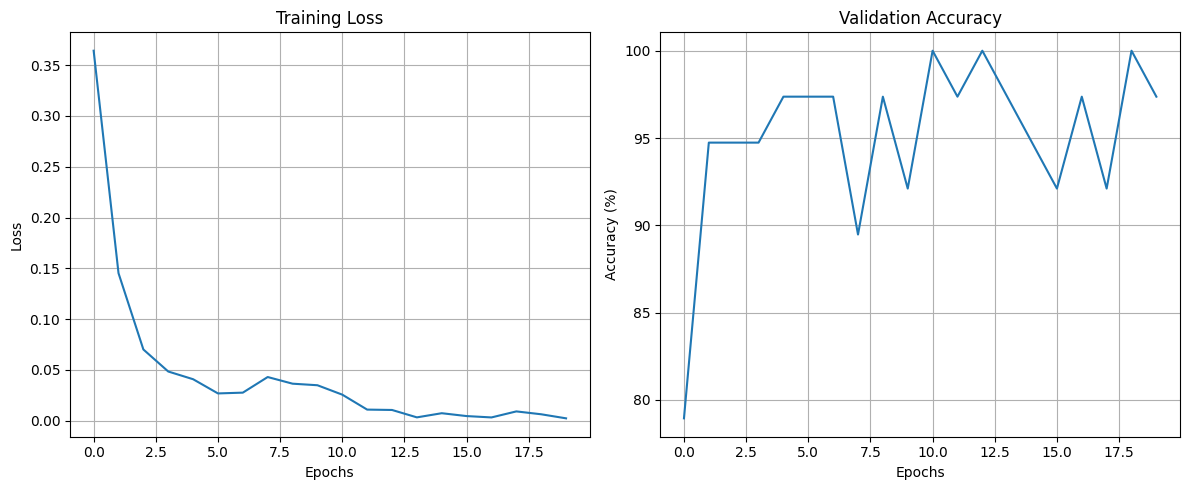

Final model saved at /content/drive/My Drive/FYP/VGGModel/Improved_20250210/final_model_vgg_improved_20250210.pth
Test Loss: 0.154089, Test Accuracy: 92.31%


In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import numpy as np
import random
import matplotlib.pyplot as plt
from datetime import datetime

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Define the device for computation
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Mount Google Drive to save and load the model (if using Google Colab)
from google.colab import drive
drive.mount('/content/drive')

# Define the folder to save model checkpoints
date_str = datetime.now().strftime('%Y%m%d')
checkpoint_folder = f'/content/drive/My Drive/FYP/VGGModel/Improved_{date_str}/'
os.makedirs(checkpoint_folder, exist_ok=True)

# Data Augmentation for Training Set
# Define Augmentations for Training Set (Keeping Image at 300x300)
transform_train = transforms.Compose([
    transforms.Resize((300, 300)),  # Change input size to 300x300
    transforms.RandomHorizontalFlip(p=0.5),  # Flip left/right
    transforms.RandomVerticalFlip(p=0.3),  # Flip up/down (not too often)
    transforms.RandomRotation(degrees=10),  # Small rotation (preserves structure)
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),  # Slight shifts
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),  # Small color changes
    transforms.RandomResizedCrop(300, scale=(0.95, 1.0)),  # Crop slightly (keeps structure)
    transforms.RandomAdjustSharpness(sharpness_factor=1.2, p=0.3),  # Enhance details slightly
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # Standard normalization
])

# Define Augmentations for Validation & Test Set (No aggressive modifications)
transform_val_test = transforms.Compose([
    transforms.Resize((300, 300)),  # Resize to match training size
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # Keep normalization same as training
])

# Load datasets
data_path = '/content/drive/My Drive/FYP/Dataset/HQ3/train'
test_data_path = '/content/drive/My Drive/FYP/Dataset/HQ3/test'
train_dataset = datasets.ImageFolder(data_path, transform=transform_train)
test_dataset = datasets.ImageFolder(test_data_path, transform=transform_val_test)

# Split the dataset into 95% training and 5% validation
train_size = int(0.95 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

# Create data loaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

#######################################
# Define a simple Squeeze-and-Excitation (SE) block for channel attention
#######################################
class SEBlock(nn.Module):
    def __init__(self, channel, reduction=16):
        super(SEBlock, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channel // reduction, channel, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y

#######################################
# Improved VGG-16 model with custom classifier and attention module
#######################################
class VGG16Improved(nn.Module):
    def __init__(self, num_classes=2, freeze_layers=True):
        super(VGG16Improved, self).__init__()
        self.vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

        # Optionally freeze early layers
        if freeze_layers:
            for param in self.vgg.features[:24].parameters():
                param.requires_grad = False

        self.attention = SEBlock(channel=512, reduction=16)

        # Pass a dummy input through features to determine the flattened size
        dummy = torch.zeros(1, 3, 300, 300)
        dummy = self.vgg.features(dummy)
        # Option 1: Use AdaptiveAvgPool2d to force a fixed shape
        dummy = nn.AdaptiveAvgPool2d((7, 7))(dummy)
        flattened_size = dummy.view(1, -1).size(1)  # Should be 25088

        # Replace the classifier with a custom one using the computed flattened_size
        self.vgg.classifier = nn.Sequential(
            nn.Linear(flattened_size, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, 1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        x = self.vgg.features(x)
        x = self.attention(x)
        # Optionally use adaptive pooling here as well (if not computed dynamically)
        x = nn.AdaptiveAvgPool2d((7, 7))(x)
        x = x.view(x.size(0), -1)
        x = self.vgg.classifier(x)
        return x

# Initialize the improved VGG model
model = VGG16Improved(num_classes=2, freeze_layers=True).to(device)

# Define loss function and optimizer (only update parameters with requires_grad=True)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                        lr=1e-4, weight_decay=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.1, patience=3)

#######################################
# Training loop with learning rate scheduler
# The code saves the current model every epoch (overwriting the previous saved model)
# and also saves a separate file if the model has a new best validation accuracy.
#######################################
def train(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs=20):
    best_acc = 0.0
    train_losses = []
    val_accuracies = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)  # Gradient clipping
            optimizer.step()
            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {train_loss:.6f}")

        # Validate the model
        val_acc = validate(model, val_loader, criterion)
        val_accuracies.append(val_acc)
        scheduler.step(val_acc)

        # Save the current epoch's model (overwrite previous saved model)
        current_model_path = os.path.join(checkpoint_folder, "current_model_vgg_improved.pth")
        torch.save(model.state_dict(), current_model_path)
        print(f"Current model saved at {current_model_path}")

        # Save the best model (if current epoch improved validation accuracy)
        if val_acc > best_acc:
            best_acc = val_acc
            best_model_path = os.path.join(checkpoint_folder, f"best_model_vgg_improved_{date_str}.pth")
            torch.save(model.state_dict(), best_model_path)
            print(f"New best model saved with accuracy: {best_acc:.2f}% at {best_model_path}")

    # Plot training and validation metrics
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Training Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training Loss')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.title('Validation Accuracy')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    # Finally, save the model from the last epoch as the final model
    final_model_path = os.path.join(checkpoint_folder, f"final_model_vgg_improved_{date_str}.pth")
    torch.save(model.state_dict(), final_model_path)
    print(f"Final model saved at {final_model_path}")

#######################################
# Validation loop returning accuracy
#######################################
def validate(model, loader, criterion):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f'Validation Accuracy: {accuracy:.2f}%')
    return accuracy

#######################################
# Test function to evaluate on the test set
#######################################
def test(model, loader, criterion):
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f'Test Loss: {test_loss/len(loader):.6f}, Test Accuracy: {accuracy:.2f}%')

#######################################
# Step 1: Train the improved model with learning rate scheduling
#######################################
train(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs=20)

#######################################
# Step 2: Evaluate the model on the test set
#######################################
test(model, test_loader, criterion)


<ipython-input-5-6d161a949a72>:76: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(checkpoint_path, map_location=device)


Model loaded successfully.

Processing: /content/drive/My Drive/FYP/Dataset/HQ3/train/Slaty_Backed_Gull/011sm.jpg


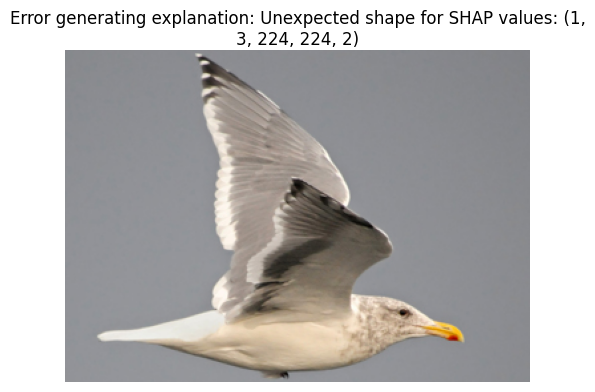


Processing: /content/drive/My Drive/FYP/Dataset/HQ3/train/Slaty_Backed_Gull/480 (42).jpeg


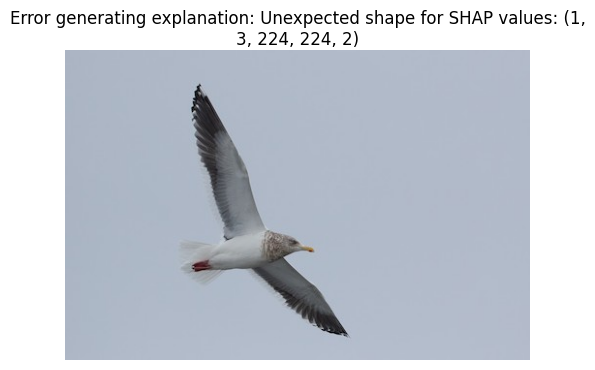


Processing: /content/drive/My Drive/FYP/Dataset/HQ3/train/Slaty_Backed_Gull/480 (9).jpeg


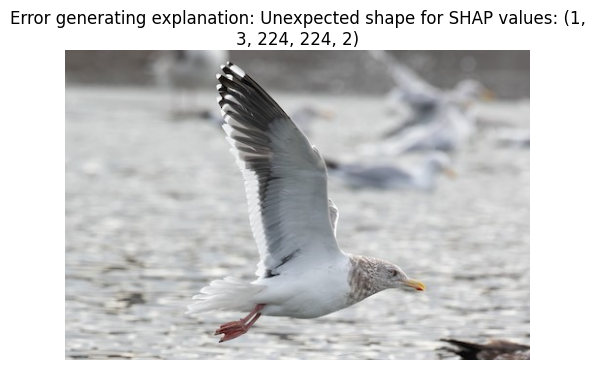


Processing: /content/drive/My Drive/FYP/Dataset/HQ3/train/Slaty_Backed_Gull/480 (52).jpeg


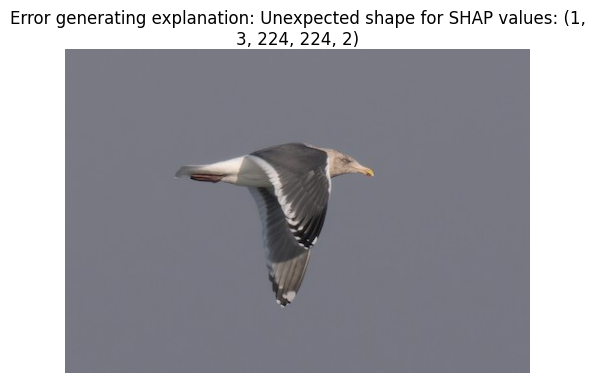


Processing: /content/drive/My Drive/FYP/Dataset/HQ3/train/Slaty_Backed_Gull/007.jpg


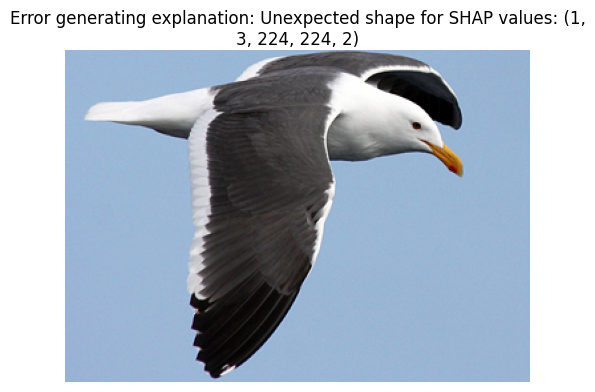


Processing: /content/drive/My Drive/FYP/Dataset/HQ3/train/Glaucous_Winged_Gull/iDFGmages.jpg


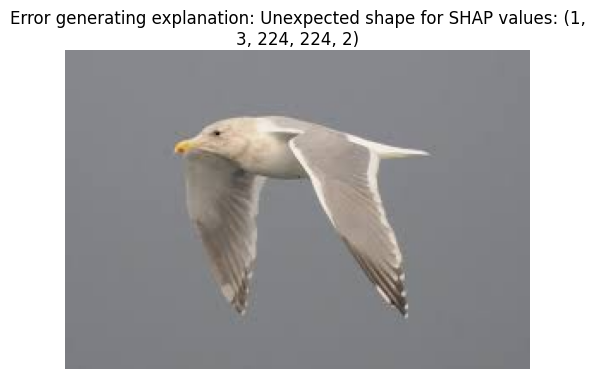


Processing: /content/drive/My Drive/FYP/Dataset/HQ3/train/Glaucous_Winged_Gull/imageRTEs.jpg


In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import cv2
import shap
from torchvision import models, transforms
from PIL import Image
import random

# ------------------------------------
# 1. Define the SEBlock (Squeeze-and-Excitation)
# ------------------------------------
class SEBlock(nn.Module):
    def __init__(self, channel, reduction=16):
        super(SEBlock, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channel // reduction, channel, bias=False),
            nn.Sigmoid()
        )
    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y

# ------------------------------------
# 2. Define the Modified VGG16 Model with SEBlock
# ------------------------------------
class VGG16Improved(nn.Module):
    def __init__(self, num_classes=2, freeze_layers=True):
        super(VGG16Improved, self).__init__()
        # Load the pretrained VGG16 model
        self.vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        # Optionally freeze early layers
        if freeze_layers:
            for param in self.vgg.features[:24].parameters():
                param.requires_grad = False
        # Add the SEBlock after the features
        self.attention = SEBlock(channel=512, reduction=16)
        # Determine the flattened size by passing a dummy image
        dummy = torch.zeros(1, 3, 300, 300)
        dummy = self.vgg.features(dummy)
        dummy = nn.AdaptiveAvgPool2d((7, 7))(dummy)
        flattened_size = dummy.view(1, -1).size(1)
        # Replace the classifier with a custom one
        self.vgg.classifier = nn.Sequential(
            nn.Linear(flattened_size, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, 1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes)
        )
    def forward(self, x):
        x = self.vgg.features(x)
        x = self.attention(x)
        x = nn.AdaptiveAvgPool2d((7, 7))(x)
        x = x.view(x.size(0), -1)
        x = self.vgg.classifier(x)
        return x

# ------------------------------------
# 3. Load the Trained Model
# ------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = '/content/drive/My Drive/FYP/VGGModel/Improved_20250210/final_model_vgg_improved_20250210.pth'
model = VGG16Improved()
# Note: The warning about torch.load and pickle is a security notice.
# If you are loading a trusted model file, you may ignore it.
state_dict = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(state_dict, strict=False)
model.to(device)
model.eval()
print("Model loaded successfully.")

# Define class names (adjust as needed)
class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

# ------------------------------------
# 4. Define Image Transformations
# ------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# ------------------------------------
# 5. SHAP Explainability with Textual Explanation
# ------------------------------------
def explain_with_shap(image_tensor, model, class_names):
    """
    Generates a textual explanation for the model prediction using SHAP.
    It computes per-channel importance and maps each channel to a placeholder feature.
    """
    # Get the predicted class
    output = model(image_tensor)
    target_class = torch.argmax(output, dim=1).item()

    # Create the SHAP explainer using the input image as the background
    explainer = shap.GradientExplainer(model, image_tensor)
    shap_values = explainer.shap_values(image_tensor)

    # Select the SHAP values corresponding to the target class.
    # Sometimes, shap_values might be a list with one element.
    if isinstance(shap_values, list):
        if len(shap_values) > target_class:
            shap_vals = shap_values[target_class]
        else:
            shap_vals = shap_values[0]
    else:
        shap_vals = shap_values

    # Check the shape: It might be channels-first (1, 3, H, W) or channels-last (1, H, W, 3)
    if shap_vals.ndim == 4:
        if shap_vals.shape[1] == 3:
            # Channels-first format
            channel_importance = np.abs(shap_vals).mean(axis=(0, 2, 3))
        elif shap_vals.shape[-1] == 3:
            # Channels-last format
            channel_importance = np.abs(shap_vals).mean(axis=(0, 1, 2))
        else:
            raise ValueError("Unexpected number of channels in SHAP values: " + str(shap_vals.shape))
    else:
        raise ValueError("Unexpected shape for SHAP values: " + str(shap_vals.shape))

    # Sort channel indices by importance (largest first)
    sorted_indices = np.argsort(channel_importance)[::-1]

    # Map channels to feature names.
    # Here we assume: channel 0 = Red -> "feather tone",
    #              channel 1 = Green -> "wing pattern",
    #              channel 2 = Blue -> "beak shape"
    channel_to_feature = {0: "feather tone", 1: "wing pattern", 2: "beak shape"}
    # Ensure we only use channels 0,1,2 (if sorted_indices contains unexpected indices, filter them)
    top_features = []
    for i in sorted_indices:
        if i in channel_to_feature:
            top_features.append(channel_to_feature[int(i)])
        if len(top_features) == 3:
            break
    # In case we don't have three valid channels (should not happen), pad with "unknown feature"
    while len(top_features) < 3:
        top_features.append("unknown feature")

    explanation = (
        f"The model predicted '{class_names[target_class]}' because it detected strong signals "
        f"in {top_features[0]}, {top_features[1]}, and {top_features[2]}."
    )
    return explanation

# ------------------------------------
# 6. Function to Process a Single Image and Show Explanation
# ------------------------------------
def process_image_with_explanation(image_path, model):
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)

    try:
        # Get the SHAP textual explanation
        explanation_text = explain_with_shap(image_tensor, model, class_names)
    except Exception as e:
        explanation_text = f"Error generating explanation: {e}"

    # Display the image with the explanation as the title
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis('off')
    plt.title(explanation_text, fontsize=12, wrap=True)
    plt.show()

# ------------------------------------
# 7. Process Test Images from a Folder
# ------------------------------------
test_folder_path = '/content/drive/My Drive/FYP/Dataset/HQ3/train/'

for subfolder in os.listdir(test_folder_path):
    subfolder_path = os.path.join(test_folder_path, subfolder)
    if not os.path.isdir(subfolder_path):
        continue

    image_files = [f for f in os.listdir(subfolder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))][:5]
    for file in image_files:
        image_path = os.path.join(subfolder_path, file)
        print(f"\nProcessing: {image_path}")
        process_image_with_explanation(image_path, model)


In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import cv2
from torchvision import models, transforms
from PIL import Image

# ------------------------------------
# Define the SEBlock (Squeeze-and-Excitation)
# ------------------------------------
class SEBlock(nn.Module):
    def __init__(self, channel, reduction=16):
        super(SEBlock, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channel // reduction, channel, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y

# ------------------------------------
# Global settings and paths
# ------------------------------------
MAX_IMAGES_PER_FOLDER = 10  # Limit images processed per folder

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define model and dataset paths
checkpoint_path = '/content/drive/My Drive/FYP/VGGModel/Improved_20250210/final_model_vgg_improved_20250210.pth'
test_folder_path = '/content/drive/My Drive/FYP/Dataset/HQ3/train/'

# Define image transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# ------------------------------------
# Define the modified VGG16 model with SEBlock attention
# ------------------------------------
class VGG16Improved(nn.Module):
    def __init__(self, num_classes=2, freeze_layers=True):
        super(VGG16Improved, self).__init__()
        self.vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

        # Optionally freeze early layers
        if freeze_layers:
            for param in self.vgg.features[:24].parameters():
                param.requires_grad = False

        # Use the SEBlock attention module
        self.attention = SEBlock(channel=512, reduction=16)

        # Pass a dummy input through features to determine the flattened size
        dummy = torch.zeros(1, 3, 300, 300)
        dummy = self.vgg.features(dummy)
        dummy = nn.AdaptiveAvgPool2d((7, 7))(dummy)
        flattened_size = dummy.view(1, -1).size(1)  # Typically 25088

        # Replace the classifier with a custom one using the computed flattened_size
        self.vgg.classifier = nn.Sequential(
            nn.Linear(flattened_size, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, 1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        x = self.vgg.features(x)
        x = self.attention(x)
        x = nn.AdaptiveAvgPool2d((7, 7))(x)
        x = x.view(x.size(0), -1)
        x = self.vgg.classifier(x)
        return x

# ------------------------------------
# Function to load the trained model
# ------------------------------------
def load_model(checkpoint_path):
    model = VGG16Improved()
    state_dict = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state_dict, strict=False)
    model.to(device)
    model.eval()
    return model

# Load the model
model = load_model(checkpoint_path)
print("Model loaded successfully.")

# Define class names
class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

# ------------------------------------
# Function to preprocess an image
# ------------------------------------
def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)
    return image_tensor

# ------------------------------------
# Grad-CAM function (computes both positive and negative maps)
# ------------------------------------
def generate_gradcam(model, image_tensor, target_layer):
    features = []
    grads = []

    # Hook to capture features
    def forward_hook(module, input, output):
        features.append(output)

    # Hook to capture gradients
    def backward_hook(module, grad_in, grad_out):
        grads.append(grad_out[0])

    # Register hooks
    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_backward_hook(backward_hook)

    # Forward pass
    output = model(image_tensor)
    # Compute prediction and confidence
    predicted_class_idx = torch.argmax(output, dim=1).item()
    probabilities = torch.softmax(output, dim=1)
    confidence = probabilities[0, predicted_class_idx].item()

    # Backward pass
    model.zero_grad()
    output[0, predicted_class_idx].backward()

    # Remove hooks
    forward_handle.remove()
    backward_handle.remove()

    # Extract feature maps and gradients
    feature_map = features[0].cpu().detach().numpy()[0]
    gradient = grads[0].cpu().detach().numpy()[0]

    # Compute weights and raw CAM
    weights = np.mean(gradient, axis=(1, 2))
    cam = np.zeros(feature_map.shape[1:], dtype=np.float32)
    for i, w in enumerate(weights):
        cam += w * feature_map[i]

    # Split CAM into positive and negative contributions
    pos_cam = np.maximum(cam, 0)
    neg_cam = np.minimum(cam, 0)
    neg_cam = -neg_cam  # Invert negative values for visualization

    # Resize and normalize both maps
    pos_cam = cv2.resize(pos_cam, (224, 224))
    pos_cam -= pos_cam.min()
    pos_cam = pos_cam / (pos_cam.max() + 1e-8)

    neg_cam = cv2.resize(neg_cam, (224, 224))
    neg_cam -= neg_cam.min()
    neg_cam = neg_cam / (neg_cam.max() + 1e-8)

    return pos_cam, neg_cam, predicted_class_idx, confidence

# ------------------------------------
# Function to visualize results (shows original image, positive and negative Grad-CAM overlays)
# ------------------------------------
def visualize_results(image_path, pos_cam, neg_cam, predicted_class, confidence):
    # Load and resize original image
    original_image = Image.open(image_path).resize((224, 224), Image.LANCZOS)
    original_image_np = np.array(original_image)

    # Create heatmaps for both maps
    heatmap_pos = cv2.applyColorMap(np.uint8(255 * pos_cam), cv2.COLORMAP_JET)
    heatmap_pos = cv2.cvtColor(heatmap_pos, cv2.COLOR_BGR2RGB)
    overlay_pos = np.clip(0.4 * heatmap_pos + 0.6 * original_image_np, 0, 255).astype(np.uint8)

    heatmap_neg = cv2.applyColorMap(np.uint8(255 * neg_cam), cv2.COLORMAP_JET)
    heatmap_neg = cv2.cvtColor(heatmap_neg, cv2.COLOR_BGR2RGB)
    overlay_neg = np.clip(0.4 * heatmap_neg + 0.6 * original_image_np, 0, 255).astype(np.uint8)

    # Plot the original image along with both overlays
    plt.figure(figsize=(18, 6))

    plt.subplot(1, 3, 1)
    plt.title(f"Original Image\nPredicted: {class_names[predicted_class]}\nConfidence: {confidence:.2f}")
    plt.imshow(original_image_np)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title("Positive Contribution Grad-CAM")
    plt.imshow(overlay_pos)
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title("Negative Contribution Grad-CAM")
    plt.imshow(overlay_neg)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# ------------------------------------
# Function to process the test folder
# ------------------------------------
def process_test_folder(test_folder_path, model):
    # Use the last convolutional layer as the target for Grad-CAM
    target_layer = model.vgg.features[-1]

    for subfolder in os.listdir(test_folder_path):
        subfolder_path = os.path.join(test_folder_path, subfolder)
        if not os.path.isdir(subfolder_path):
            continue

        print(f"\nProcessing folder: {subfolder_path}")
        image_files = [f for f in os.listdir(subfolder_path)
                       if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        image_files = image_files[:MAX_IMAGES_PER_FOLDER]

        for file in image_files:
            image_path = os.path.join(subfolder_path, file)
            print(f"\nProcessing: {image_path}")
            try:
                image_tensor = preprocess_image(image_path)
                pos_cam, neg_cam, predicted_class_idx, confidence = generate_gradcam(model, image_tensor, target_layer)
                visualize_results(image_path, pos_cam, neg_cam, predicted_class_idx, confidence)
            except Exception as e:
                print(f"Error processing {image_path}: {e}")

# ------------------------------------
# Execute the pipeline
# ------------------------------------
process_test_folder(test_folder_path, model)


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import cv2
from torchvision import models, transforms
from PIL import Image

# ------------------------------------
# Define the SEBlock (Squeeze-and-Excitation)
# ------------------------------------
class SEBlock(nn.Module):
    def __init__(self, channel, reduction=16):
        super(SEBlock, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channel // reduction, channel, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y

# ------------------------------------
# Global settings and device configuration
# ------------------------------------
MAX_IMAGES_PER_FOLDER = 10  # Limit images processed per folder
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define model and dataset paths (adjust these as needed)
checkpoint_path = '/content/drive/My Drive/FYP/VGGModel/Improved_20250210/current_model_vgg_improved.pth'
test_folder_path = '/content/drive/My Drive/FYP/Dataset/HQ3/train/'

# Define image transformations
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# ------------------------------------
# Define the modified VGG16 model with SEBlock attention
# ------------------------------------
class VGG16Improved(nn.Module):
    def __init__(self, num_classes=2, freeze_layers=True):
        super(VGG16Improved, self).__init__()
        self.vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

        # Optionally freeze early layers
        if freeze_layers:
            for param in self.vgg.features[:24].parameters():
                param.requires_grad = False

        # Use the SEBlock attention module
        self.attention = SEBlock(channel=512, reduction=16)

        # Pass a dummy input through features to determine the flattened size
        dummy = torch.zeros(1, 3, 300, 300)
        dummy = self.vgg.features(dummy)
        dummy = nn.AdaptiveAvgPool2d((7, 7))(dummy)
        flattened_size = dummy.view(1, -1).size(1)  # Typically 25088

        # Replace the classifier with a custom one using the computed flattened_size
        self.vgg.classifier = nn.Sequential(
            nn.Linear(flattened_size, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(4096, 1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        x = self.vgg.features(x)
        x = self.attention(x)
        x = nn.AdaptiveAvgPool2d((7, 7))(x)
        x = x.view(x.size(0), -1)
        x = self.vgg.classifier(x)
        return x

# ------------------------------------
# Function to load the trained model
# ------------------------------------
def load_model(checkpoint_path):
    model = VGG16Improved()
    state_dict = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state_dict, strict=False)
    model.to(device)
    model.eval()
    return model

# Load the model
model = load_model(checkpoint_path)
print("Model loaded successfully.")

# Define class names
class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']

# ------------------------------------
# Function to preprocess an image
# ------------------------------------
def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)
    return image_tensor

# ------------------------------------
# Existing Grad-CAM mechanism (computes both positive and negative maps)
# ------------------------------------
def generate_gradcam(model, image_tensor, target_layer):
    features = []
    grads = []

    # Hook to capture features
    def forward_hook(module, input, output):
        features.append(output)

    # Hook to capture gradients
    def backward_hook(module, grad_in, grad_out):
        grads.append(grad_out[0])

    # Register hooks
    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_backward_hook(backward_hook)

    # Forward pass
    output = model(image_tensor)
    predicted_class_idx = torch.argmax(output, dim=1).item()
    probabilities = torch.softmax(output, dim=1)
    confidence = probabilities[0, predicted_class_idx].item()

    # Backward pass
    model.zero_grad()
    output[0, predicted_class_idx].backward()

    # Remove hooks
    forward_handle.remove()
    backward_handle.remove()

    # Extract feature maps and gradients
    feature_map = features[0].cpu().detach().numpy()[0]
    gradient = grads[0].cpu().detach().numpy()[0]

    # Compute weights and raw CAM
    weights = np.mean(gradient, axis=(1, 2))
    cam = np.zeros(feature_map.shape[1:], dtype=np.float32)
    for i, w in enumerate(weights):
        cam += w * feature_map[i]

    # Split CAM into positive and negative contributions
    pos_cam = np.maximum(cam, 0)
    neg_cam = np.minimum(cam, 0)
    neg_cam = -neg_cam  # Invert negative values for visualization

    # Resize and normalize both maps
    pos_cam = cv2.resize(pos_cam, (224, 224))
    pos_cam -= pos_cam.min()
    pos_cam = pos_cam / (pos_cam.max() + 1e-8)

    neg_cam = cv2.resize(neg_cam, (224, 224))
    neg_cam -= neg_cam.min()
    neg_cam = neg_cam / (neg_cam.max() + 1e-8)

    return pos_cam, neg_cam, predicted_class_idx, confidence

# ------------------------------------
# Function to visualize Grad-CAM results
# ------------------------------------
def visualize_results(image_path, pos_cam, neg_cam, predicted_class, confidence):
    # Load and resize original image
    original_image = Image.open(image_path).resize((224, 224), Image.LANCZOS)
    original_image_np = np.array(original_image)

    # Create heatmaps for both maps
    heatmap_pos = cv2.applyColorMap(np.uint8(255 * pos_cam), cv2.COLORMAP_JET)
    heatmap_pos = cv2.cvtColor(heatmap_pos, cv2.COLOR_BGR2RGB)
    overlay_pos = np.clip(0.4 * heatmap_pos + 0.6 * original_image_np, 0, 255).astype(np.uint8)

    heatmap_neg = cv2.applyColorMap(np.uint8(255 * neg_cam), cv2.COLORMAP_JET)
    heatmap_neg = cv2.cvtColor(heatmap_neg, cv2.COLOR_BGR2RGB)
    overlay_neg = np.clip(0.4 * heatmap_neg + 0.6 * original_image_np, 0, 255).astype(np.uint8)

    # Plot the original image along with both overlays
    plt.figure(figsize=(18, 6))

    plt.subplot(1, 3, 1)
    plt.title(f"Original Image\nPredicted: {class_names[predicted_class]}\nConfidence: {confidence:.2f}")
    plt.imshow(original_image_np)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title("Positive Contribution Grad-CAM")
    plt.imshow(overlay_pos)
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title("Negative Contribution Grad-CAM")
    plt.imshow(overlay_neg)
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# ------------------------------------
# NEW: Integrated Gradients implementation
# ------------------------------------
def integrated_gradients(model, input_tensor, target_class=None, baseline=None, steps=50):
    """
    Computes Integrated Gradients for the given input.
    Args:
        model: the neural network
        input_tensor: the preprocessed input (1, C, H, W)
        target_class: index of target class; if None, uses predicted class
        baseline: baseline tensor (if None, a tensor of zeros is used)
        steps: number of interpolation steps
    Returns:
        integrated_grad: attribution map of same shape as input_tensor
    """
    if baseline is None:
        baseline = torch.zeros_like(input_tensor).to(device)
    if target_class is None:
        output = model(input_tensor)
        target_class = torch.argmax(output, dim=1).item()

    # Generate scaled inputs
    scaled_inputs = [baseline + (float(i) / steps) * (input_tensor - baseline) for i in range(0, steps + 1)]
    grads = []
    for scaled_input in scaled_inputs:
        scaled_input = scaled_input.requires_grad_(True)
        output = model(scaled_input)
        model.zero_grad()
        output[0, target_class].backward(retain_graph=True)
        grad = scaled_input.grad.detach()
        grads.append(grad)
    grads = torch.stack(grads)  # shape: (steps+1, 1, C, H, W)
    avg_grad = grads.mean(dim=0)
    integrated_grad = (input_tensor - baseline) * avg_grad
    return integrated_grad

# ------------------------------------
# NEW: Guided Backpropagation implementation
# ------------------------------------
class GuidedBackprop:
    def __init__(self, model):
        self.model = model
        self.model.eval()
        self.handlers = []
        # Register backward hooks on every ReLU module
        for module in self.model.modules():
            if isinstance(module, nn.ReLU):
                handler = module.register_backward_hook(self.relu_backward_hook)
                self.handlers.append(handler)

    def relu_backward_hook(self, module, grad_in, grad_out):
        # Only allow positive gradients to pass
        return (torch.clamp(grad_in[0], min=0.0),)

    def generate_gradients(self, input_tensor, target_class):
        input_tensor = input_tensor.clone().requires_grad_(True)
        output = self.model(input_tensor)
        self.model.zero_grad()
        output[0, target_class].backward()
        return input_tensor.grad.data.cpu().numpy()[0]

    def remove_hooks(self):
        for handler in self.handlers:
            handler.remove()

# ------------------------------------
# NEW: Function to visualize Integrated Gradients and Guided Backpropagation results
# ------------------------------------
def visualize_interpretability(image_path, integrated_grad, guided_grad, predicted_class, confidence):
    # Load and resize original image
    original_image = Image.open(image_path).resize((224, 224), Image.LANCZOS)
    original_image_np = np.array(original_image)

    # Process Integrated Gradients result:
    # (squeeze batch dim, then rearrange to H x W x C)
    integrated_grad_np = integrated_grad.squeeze(0).cpu().detach().numpy()  # shape (C, H, W)
    integrated_grad_np = np.transpose(integrated_grad_np, (1, 2, 0))
    # Summing absolute values across channels yields a coarse heatmap
    integrated_grad_heatmap = np.sum(np.abs(integrated_grad_np), axis=-1)
    integrated_grad_heatmap = cv2.resize(integrated_grad_heatmap, (224, 224))
    integrated_grad_heatmap = (integrated_grad_heatmap - integrated_grad_heatmap.min()) / (integrated_grad_heatmap.max() + 1e-8)

    # Process Guided Backpropagation result:
    guided_grad = np.transpose(guided_grad, (1, 2, 0))
    guided_grad_heatmap = np.sum(np.abs(guided_grad), axis=-1)
    guided_grad_heatmap = cv2.resize(guided_grad_heatmap, (224, 224))
    guided_grad_heatmap = (guided_grad_heatmap - guided_grad_heatmap.min()) / (guided_grad_heatmap.max() + 1e-8)

    # Create color heatmaps and overlay on original image
    heatmap_integrated = cv2.applyColorMap(np.uint8(255 * integrated_grad_heatmap), cv2.COLORMAP_JET)
    heatmap_integrated = cv2.cvtColor(heatmap_integrated, cv2.COLOR_BGR2RGB)
    overlay_integrated = np.clip(0.4 * heatmap_integrated + 0.6 * original_image_np, 0, 255).astype(np.uint8)

    heatmap_guided = cv2.applyColorMap(np.uint8(255 * guided_grad_heatmap), cv2.COLORMAP_JET)
    heatmap_guided = cv2.cvtColor(heatmap_guided, cv2.COLOR_BGR2RGB)
    overlay_guided = np.clip(0.4 * heatmap_guided + 0.6 * original_image_np, 0, 255).astype(np.uint8)

    # Plot the visualizations
    plt.figure(figsize=(18, 6))
    plt.subplot(1, 3, 1)
    plt.imshow(original_image_np)
    plt.axis('off')
    plt.title(f"Original Image\nPredicted: {class_names[predicted_class]}\nConfidence: {confidence:.2f}")

    plt.subplot(1, 3, 2)
    plt.imshow(overlay_integrated)
    plt.axis('off')
    plt.title("Integrated Gradients")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay_guided)
    plt.axis('off')
    plt.title("Guided Backpropagation")

    plt.tight_layout()
    plt.show()

# ------------------------------------
# NEW: Function to process the test folder using all interpretability methods
# ------------------------------------
def process_test_folder_interpretability(test_folder_path, model):
    # For Grad-CAM, use the last convolutional layer
    target_layer = model.vgg.features[-1]
    for subfolder in os.listdir(test_folder_path):
        subfolder_path = os.path.join(test_folder_path, subfolder)
        if not os.path.isdir(subfolder_path):
            continue

        print(f"\nProcessing folder: {subfolder_path}")
        image_files = [f for f in os.listdir(subfolder_path)
                       if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        image_files = image_files[:MAX_IMAGES_PER_FOLDER]

        for file in image_files:
            image_path = os.path.join(subfolder_path, file)
            print(f"\nProcessing: {image_path}")
            try:
                image_tensor = preprocess_image(image_path)

                # Forward pass to get prediction and confidence
                output = model(image_tensor)
                predicted_class_idx = torch.argmax(output, dim=1).item()
                confidence = torch.softmax(output, dim=1)[0, predicted_class_idx].item()

                # -----------------------------
                # 1. Grad-CAM (existing)
                # -----------------------------
                pos_cam, neg_cam, _, _ = generate_gradcam(model, image_tensor, target_layer)
                visualize_results(image_path, pos_cam, neg_cam, predicted_class_idx, confidence)

                # -----------------------------
                # 2. Integrated Gradients
                # -----------------------------
                integrated_grad = integrated_gradients(model, image_tensor, target_class=predicted_class_idx, steps=50)

                # -----------------------------
                # 3. Guided Backpropagation
                # -----------------------------
                guided_bp = GuidedBackprop(model)
                guided_grad = guided_bp.generate_gradients(image_tensor, target_class=predicted_class_idx)
                guided_bp.remove_hooks()

                # Visualize the new interpretability maps side by side
                visualize_interpretability(image_path, integrated_grad, guided_grad, predicted_class_idx, confidence)

            except Exception as e:
                print(f"Error processing {image_path}: {e}")

# ------------------------------------
# Execute the pipeline
# ------------------------------------
process_test_folder_interpretability(test_folder_path, model)


Output hidden; open in https://colab.research.google.com to view.